# Перенос прямоугольного импульса по кольцу

В зелёном уровне переносили гладкий профиль. Теперь возьмём
$$u_0(x)=\begin{cases}1,&0.2\leq x<0.4,\\0,&\text{вне этого участка},\end{cases}$$
и решим то же уравнение $u_t+u_x=0$ на кольце $x\in[0,1)$. Точное решение — сдвиг $u(x,t)=u_0((x-t)\bmod1)$: форма и высота импульса сохраняются.

Посмотрим, что происходит с фронтами при $C=0.5$, $0.8$ и $1$. Затем отдельно проверим $C=1.1$. Отрицательные значения и превышения единицы оставляем в расчёте.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import re

plt.rcParams.update({
    "figure.dpi": 85,
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "animation.embed_limit": 70,
})

c = 1.0
methods = ["Upwind", "Лакс–Вендрофф"]
method_colors = ["#2563eb", "#df7620"]
courants = [0.5, 0.8, 1.0]
sizes = [50, 100, 200, 400]
N_plot = 200


## 1. Схемы и расчёт ошибок

Используем схемы из зелёной работы. Для $c=1$ они имеют вид
$$u_j^{n+1}=u_j^n-C(u_j^n-u_{j-1}^n)\qquad\text{(upwind)},$$
$$u_j^{n+1}=u_j^n-\frac C2(u_{j+1}^n-u_{j-1}^n)
+\frac{C^2}{2}(u_{j+1}^n-2u_j^n+u_{j-1}^n)\qquad\text{(Лакс–Вендрофф)}.$$

Индексы замыкаем по кольцу. Сетка содержит $N$ узлов без повторения $x=1$, шаг $\Delta x=1/N$. При сгущении сохраняем $C$, выбирая $\Delta t=C\Delta x$. Последний шаг до заданного момента при необходимости уменьшаем.

После каждого шага вычисляем $E_1=\Delta x\sum_j|u_j-u(x_j,t)|$, минимум и максимум. Сравниваем значения в узлах; численные решения не интерпретируем как средние по ячейкам.


In [2]:
def exact(x, t):
    phase = np.remainder(np.asarray(x) - c*t, 1.0)
    # На границах импульса убираем погрешность сравнения дробных чисел.
    for edge in [0.2, 0.4]:
        phase = np.where(np.abs(phase - edge) < 32*np.finfo(float).eps, edge, phase)
    return ((phase >= 0.2) & (phase < 0.4)).astype(float)


def upwind_step(u, C):
    return u - C * (u - np.roll(u, 1))


def lax_wendroff_step(u, C):
    left, right = np.roll(u, 1), np.roll(u, -1)
    return u - 0.5*C*(right - left) + 0.5*C**2*(right - 2*u + left)


def simulate(N, C, targets=(1.0, 5.0), keep=False):
    dx = 1.0 / N
    dt_nominal = C * dx / c
    x = np.arange(N) * dx
    u = np.stack([exact(x, 0), exact(x, 0)])
    times = [0.0]
    minima = [u.min(axis=1)]
    maxima = [u.max(axis=1)]
    errors = [dx * np.sum(np.abs(u - exact(x, 0)), axis=1)]
    history = [u.copy()] if keep else None
    snapshots = {}
    t = 0.0
    for target in targets:
        start = t
        count = int(np.ceil((target - start) / dt_nominal - 1e-12))
        for k in range(count):
            next_t = min(start + (k + 1)*dt_nominal, target)
            C_step = c * (next_t - (start + k*dt_nominal)) / dx
            if abs(C_step - C) < 1e-12:
                C_step = C
            u = np.stack([upwind_step(u[0], C_step),
                          lax_wendroff_step(u[1], C_step)])
            t = next_t
            times.append(t)
            minima.append(u.min(axis=1))
            maxima.append(u.max(axis=1))
            errors.append(dx * np.sum(np.abs(u - exact(x, t)), axis=1))
            if keep:
                history.append(u.copy())
        snapshots[target] = u.copy()
    return {
        "x": x, "dx": dx, "t": np.array(times), "snapshots": snapshots,
        "min": np.array(minima), "max": np.array(maxima), "E1": np.array(errors),
        "history": np.array(history) if keep else None,
    }


runs = {(N, C): simulate(N, C, keep=(N == N_plot))
        for C in courants for N in sizes}


## 2. Форма импульса и оба фронта

Сравним решения после одного оборота, при $t=1$, на сетке $N=200$. Ниже отдельно увеличим левый и правый фронты. Во всех увеличенных фрагментах одинаковы ширина окна и вертикальный масштаб.


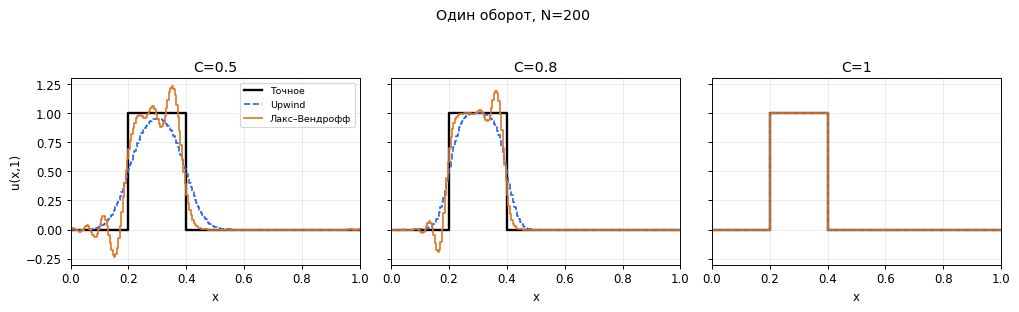

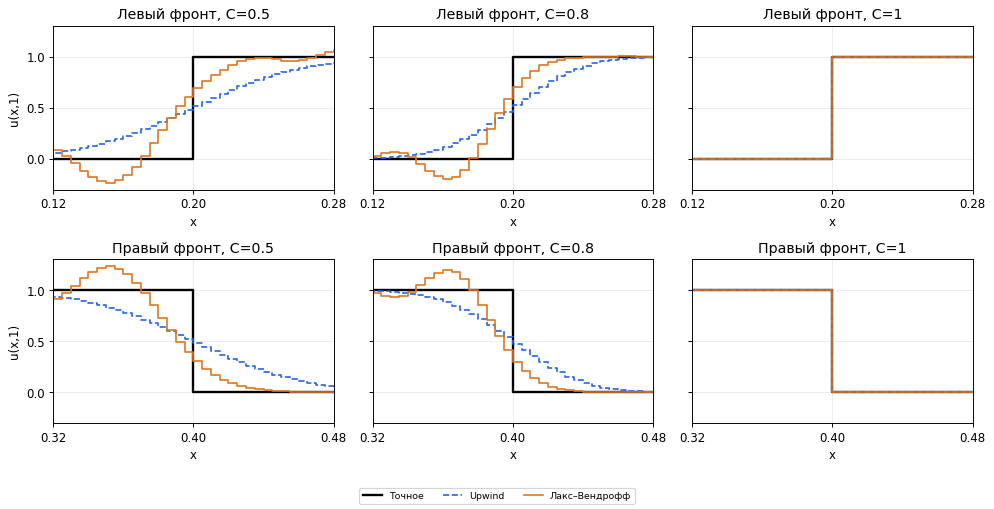

In [3]:
def draw_profile(ax, result, target):
    x = np.r_[result["x"], 1.0]
    truth = exact(x, target)
    ax.step(x, truth, where="post", color="black", lw=2, label="Точное")
    for j, (name, color) in enumerate(zip(methods, method_colors)):
        values = result["snapshots"][target][j]
        ax.step(x, np.r_[values, values[0]], where="post", color=color,
                ls="--" if j == 0 else "-", lw=1.4, label=name)


fig, axes = plt.subplots(1, 3, figsize=(12, 3.7), sharey=True)
for a, C in zip(axes, courants):
    draw_profile(a, runs[N_plot, C], 1.0)
    a.set(title=f"C={C:g}", xlabel="x", xlim=(0, 1), ylim=(-0.3, 1.3))
axes[0].set_ylabel("u(x,1)")
axes[0].legend(fontsize=8)
fig.suptitle("Один оборот, N=200")
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharey=True)
for col, C in enumerate(courants):
    for row, edge in enumerate([0.2, 0.4]):
        a = axes[row, col]
        draw_profile(a, runs[N_plot, C], 1.0)
        a.set(xlim=(edge - 0.08, edge + 0.08), ylim=(-0.3, 1.3), xlabel="x",
              title=f"{'Левый' if row == 0 else 'Правый'} фронт, C={C:g}")
        a.set_xticks([edge - 0.08, edge, edge + 0.08],
                     [f"{edge - 0.08:.2f}", f"{edge:.2f}", f"{edge + 0.08:.2f}"])
        if col == 0:
            a.set_ylabel("u(x,1)")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=8)
fig.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()


Upwind превращает скачки в плавные переходы, а высота импульса при дальнейшем переносе уменьшается. У Лакса–Вендроффа фронт уже, но рядом со скачком появляются значения ниже нуля и выше единицы. Они видны без увеличения вертикального масштаба.

При $C=1$ обе формулы сокращаются до $u_j^{n+1}=u_{j-1}^n$. За один шаг точный профиль тоже смещается на один узел. Поэтому в этом случае значения в узлах совпадают с точными; на выбранных сетках моменты $t=1$ и $5$ достигаются целым числом таких шагов.


## 3. Сгущение сетки

Для каждого $C$ сравним четыре сетки в один момент $t=1$. Уменьшение шага должно сужать область искажения фронта. При этом уменьшение интегральной ошибки ещё не означает, что исчезают локальные выбросы.


После одного оборота, t=1:
  C      N       Метод              E1          min u       max u
 0.5     50   Upwind            1.55908e-01     0.000055     0.680273
 0.5     50   Лакс–Вендрофф     9.85795e-02    -0.199769     1.173223
 0.5    100   Upwind            1.12511e-01     0.000000     0.841835
 0.5    100   Лакс–Вендрофф     7.39227e-02    -0.213311     1.222751
 0.5    200   Upwind            7.97373e-02     0.000000     0.954365
 0.5    200   Лакс–Вендрофф     5.16368e-02    -0.231319     1.232063
 0.5    400   Upwind            5.64013e-02     0.000000     0.995327
 0.5    400   Лакс–Вендрофф     3.44823e-02    -0.238969     1.238990
 0.8     50   Upwind            1.00957e-01     0.000000     0.881854
 0.8     50   Лакс–Вендрофф     7.78865e-02    -0.163848     1.159852
 0.8    100   Upwind            7.11153e-02     0.000000     0.975137
 0.8    100   Лакс–Вендрофф     5.16155e-02    -0.174736     1.174417
 0.8    200   Upwind            5.03744e-02     0.000000     0.9985

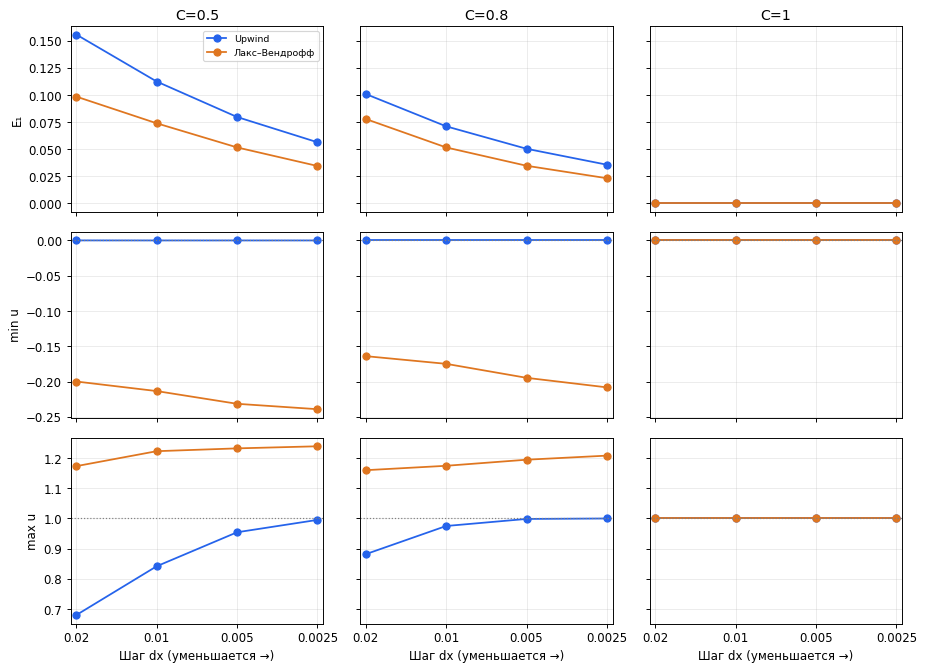

In [4]:
print("После одного оборота, t=1:")
print("  C      N       Метод              E1          min u       max u")
for C in courants:
    for N in sizes:
        result = runs[N, C]
        for j, name in enumerate(methods):
            u = result["snapshots"][1.0][j]
            E = result["dx"] * np.sum(np.abs(u - exact(result["x"], 1.0)))
            print(f"{C:4.1f}  {N:5d}   {name:16s}  {E:11.5e}  {u.min():11.6f}  {u.max():11.6f}")

fig, axes = plt.subplots(3, 3, figsize=(11, 8), sharex=True, sharey="row")
dxs = 1 / np.array(sizes, dtype=float)
for col, C in enumerate(courants):
    for j, (name, color) in enumerate(zip(methods, method_colors)):
        values = []
        for N in sizes:
            result = runs[N, C]
            u = result["snapshots"][1.0][j]
            values.append([result["dx"]*np.sum(np.abs(u - exact(result["x"], 1.0))),
                           u.min(), u.max()])
        values = np.array(values)
        for row in range(3):
            axes[row, col].plot(dxs, values[:, row], "o-", color=color, label=name)
    axes[0, col].set_title(f"C={C:g}")
    for row in range(3):
        axes[row, col].set_xscale("log")
        axes[row, col].set_xlim(dxs[0]*1.05, dxs[-1]*0.95)
        axes[row, col].minorticks_off()
        axes[row, col].set_xticks(dxs, [f"{dx:g}" for dx in dxs])
    axes[2, col].set_xlabel("Шаг dx (уменьшается →)")
    axes[1, col].axhline(0, color="0.5", ls=":", lw=1)
    axes[2, col].axhline(1, color="0.5", ls=":", lw=1)
axes[0, 0].set_ylabel("E₁")
axes[1, 0].set_ylabel("min u")
axes[2, 0].set_ylabel("max u")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()


При $C=0.8$ ошибка Лакса–Вендроффа после одного оборота уменьшилась с $0.078$ на сетке $N=50$ до $0.023$ при $N=400$. При этом минимум изменился с $-0.164$ до $-0.208$. Искажение занимает более узкую область, но его амплитуда не убывает вместе с интегральной ошибкой.

## 4. Изменение ошибки и экстремумов во времени

Проследим перенос до пяти оборотов при $N=200$. Каждому методу соответствует строка, а цвет обозначает число Куранта. Пунктирные горизонтали показывают границы исходного диапазона: 0 для минимума и 1 для максимума.

Кривые для разных C строим в общие моменты через $0.02$, которые присутствуют на всех трёх временных сетках.


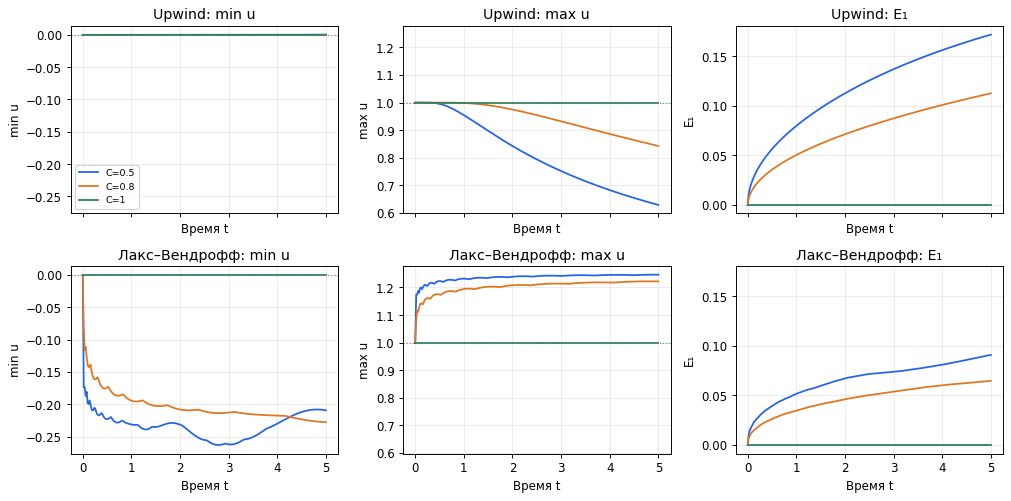

In [5]:
c_colors = ["#2563eb", "#df7620", "#21855b"]
common_times = np.arange(251) * 0.02
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True, sharey="col")
for row, name in enumerate(methods):
    for C, color in zip(courants, c_colors):
        result = runs[N_plot, C]
        indices = np.array([np.argmin(np.abs(result["t"] - tt)) for tt in common_times])
        assert np.allclose(result["t"][indices], common_times, rtol=0, atol=1e-12)
        for col, key in enumerate(["min", "max", "E1"]):
            axes[row, col].plot(common_times, result[key][indices, row], color=color, label=f"C={C:g}")
    for col, label in enumerate(["min u", "max u", "E₁"]):
        axes[row, col].set(title=f"{name}: {label}", xlabel="Время t", ylabel=label)
    axes[row, 0].axhline(0, color="0.5", ls=":", lw=1)
    axes[row, 1].axhline(1, color="0.5", ls=":", lw=1)
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()


## 5. Неустойчивый случай: C=1.1

Для рассматриваемого переноса вправо обе схемы устойчивы при $0\leq C\leq1$. Посмотрим на нарушение этого условия на той же сетке $N=200$, но только до $t=1$. Для этого расчёта используем отдельные графики: его масштаб быстро становится несопоставим с устойчивыми решениями.

У высокочастотной моды с чередованием знаков множитель за шаг равен $1-2C$ для upwind и $1-2C^2$ для Лакса–Вендроффа. При $C=1.1$ это $-1.2$ и $-1.42$: такие возмущения меняют знак и растут. Разрыв содержит высокие пространственные частоты, поэтому неустойчивость проявляется уже на этом начальном профиле.


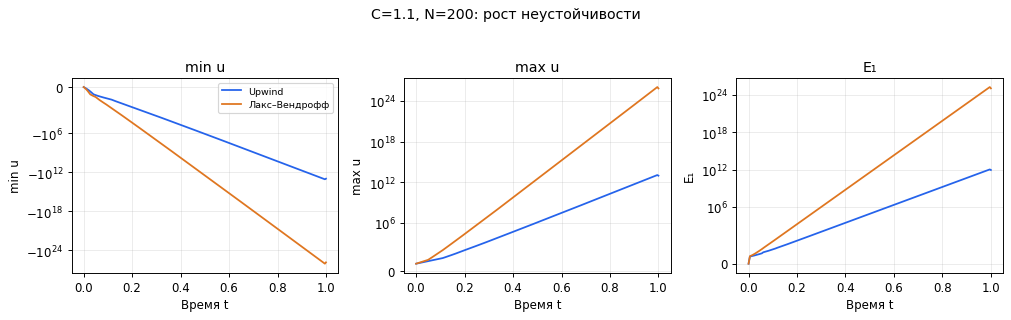

C=1.1, t=1:
Upwind            E1=8.587e+11  min=-9.352e+12  max=9.352e+12
Лакс–Вендрофф     E1=1.133e+25  min=-6.787e+25  max=6.787e+25


In [6]:
unstable = simulate(N_plot, 1.1, targets=(1.0,))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for j, (name, color) in enumerate(zip(methods, method_colors)):
    for a, key in zip(axes, ["min", "max", "E1"]):
        a.plot(unstable["t"], unstable[key][:, j], color=color, label=name)
for a, label in zip(axes, ["min u", "max u", "E₁"]):
    a.set(xlabel="Время t", ylabel=label, title=label)
    if label == "E₁":
        a.set_yscale("symlog", linthresh=0.01)
    else:
        a.set_yscale("symlog", linthresh=1)
axes[0].set_yticks([-1e24, -1e18, -1e12, -1e6, 0])
axes[1].set_yticks([0, 1e6, 1e12, 1e18, 1e24])
axes[2].set_yticks([0, 1e6, 1e12, 1e18, 1e24])
for a in axes:
    a.minorticks_off()
axes[0].legend(fontsize=8)
fig.suptitle("C=1.1, N=200: рост неустойчивости")
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

print("C=1.1, t=1:")
for j, name in enumerate(methods):
    print(f"{name:16s}  E1={unstable['E1'][-1,j]:.3e}  "
          f"min={unstable['min'][-1,j]:.3e}  max={unstable['max'][-1,j]:.3e}")


## 6. Анимация переноса

Покажем четыре оборота на сетке $N=200$. На каждой панели наложены точный профиль и оба численных решения для одного $C$. Масштабы осей одинаковы. Кадры идут через $0.04$: этот интервал кратен временным шагам всех трёх расчётов, поэтому для анимации не приходится менять число Куранта.


In [7]:
def show_animation(animation):
    html = animation.to_jshtml(fps=25, default_mode="once")
    html = re.sub(r'<link\b[^>]*font-awesome[^>]*>', '', html)
    icons = {
        "fa fa-minus": "−", "fa fa-plus": "+",
        "fa fa-fast-backward": "⏮", "fa fa-step-backward": "⏪",
        "fa fa-play fa-flip-horizontal": "◀", "fa fa-play": "▶",
        "fa fa-pause": "⏸", "fa fa-step-forward": "⏩",
        "fa fa-fast-forward": "⏭",
    }
    for css, symbol in icons.items():
        html = html.replace(f'<i class="{css}"></i>', f'<span>{symbol}</span>')
    display(HTML(html))


frame_times = np.arange(101) * 0.04
frame_indices = {}
for C in courants:
    result = runs[N_plot, C]
    indices = np.array([np.argmin(np.abs(result["t"] - tt)) for tt in frame_times])
    assert np.allclose(result["t"][indices], frame_times, rtol=0, atol=1e-12)
    frame_indices[C] = indices

fig, axes = plt.subplots(3, 1, figsize=(9.5, 7), sharex=True, sharey=True)
lines = []
for a, C in zip(axes, courants):
    result = runs[N_plot, C]
    xx = np.r_[result["x"], 1.0]
    truth_line, = a.step(xx, exact(xx, 0), where="post", color="black", lw=2, label="Точное")
    numerical_lines = []
    for j, (name, color) in enumerate(zip(methods, method_colors)):
        u = result["history"][0, j]
        line, = a.step(xx, np.r_[u, u[0]], where="post", color=color,
                       ls="--" if j == 0 else "-", lw=1.4, label=name)
        numerical_lines.append(line)
    lines.append((truth_line, numerical_lines))
    a.set(xlim=(0, 1), ylim=(-0.35, 1.35), ylabel="u", title=f"C={C:g}")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center",
           bbox_to_anchor=(0.5, 0.95), fontsize=8, ncol=3)
axes[-1].set_xlabel("x")
clock = fig.suptitle("t = 0.00", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.89])


def update(k):
    tt = frame_times[k]
    for col, C in enumerate(courants):
        result = runs[N_plot, C]
        xx = np.r_[result["x"], 1.0]
        truth_line, numerical_lines = lines[col]
        truth_line.set_ydata(exact(xx, tt))
        for j, line in enumerate(numerical_lines):
            u = result["history"][frame_indices[C][k], j]
            line.set_ydata(np.r_[u, u[0]])
    clock.set_text(f"t = {tt:.2f}")
    return clock, *[line for exact_line, pair in lines for line in [exact_line, *pair]]


animation = FuncAnimation(fig, update, frames=len(frame_times), interval=40)
plt.close(fig)
show_animation(animation)


## Вывод

**Почему более точная на гладком профиле схема даёт нефизические значения на разрыве?**

В формуле Лакса–Вендроффа при $0<C<1$ коэффициент при $u_{j+1}$ равен $(C^2-C)/2<0$. Новое значение не обязано оставаться между соседними значениями. Для гладкой функции схема точна до второго порядка, но у скачка такое приближение не предотвращает осцилляции. У upwind новое значение — выпуклая комбинация $u_j$ и $u_{j-1}$, поэтому исходный диапазон сохраняется ценой размытия фронтов.

**Почему C=1 нужно рассматривать отдельно?**

Обе схемы становятся точным сдвигом узловых значений. Нулевая ошибка в этом опыте связана с совпадением перемещения за шаг и шага сетки. При $C=0.5$ и $0.8$ остаются размытие или осцилляции, а при $C=1.1$ растёт неустойчивость.
